> **Recorded research notebook.** Executed outputs are retained from the completed study. Empirical recomputation requires the separately retained input snapshots described in `data/README.md`. Run `python scripts/reproduce_public.py` for checks and a synthetic demonstration using only this public repository. Historical publication-stage notes below describe the notebook execution date; the final PDF is now in `paper/final/Information-Diffusion-Final-Paper.pdf`.

# 04 · Learning lead–lag analysis

Three distinct ideas are often called a lag. **Event lag** asks how a response accumulates after a release. **Cross-series lag** asks whether one quoted return precedes another. **Information lag** asks whether new knowledge has already reached market participants. The first two are observable statistical descriptions; the third needs additional identification.

As Hou and Moskowitz (2005) explain in their study of price delay, lagged information in market returns can reveal price-adjustment frictions. Their principal weekly-return design differs from this minute-event exercise, so their delay measure is not relabelled as our estimate. As Hasbrouck (2007) explains, observed quote dynamics also contain market-microstructure effects.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'diffusion/common.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from diffusion.common import ROOT, design, sha256
from diffusion.reporting import table
from diffusion.presentation import show_table, show_json, show_figure, show_plot, equation
pd.set_option('display.max_columns', 12)
print('Project:', ROOT.name)
print('Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.')

Project: Information-Diffusion-Research
Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.


## A known two-minute lead

The toy example creates a target that follows a source with a two-minute delay. We correlate source at time t with target at time t+lag. Under this convention, a positive lag means the source precedes the target. Each event is demeaned within its paired window before pooling, matching the empirical diagnostic.

lag_minutes,correlation
-5,-0.017
-4,-0.047
-3,-0.017
-2,-0.018
-1,-0.021
0,-0.019
1,-0.005
2,0.981
3,-0.011
4,-0.017


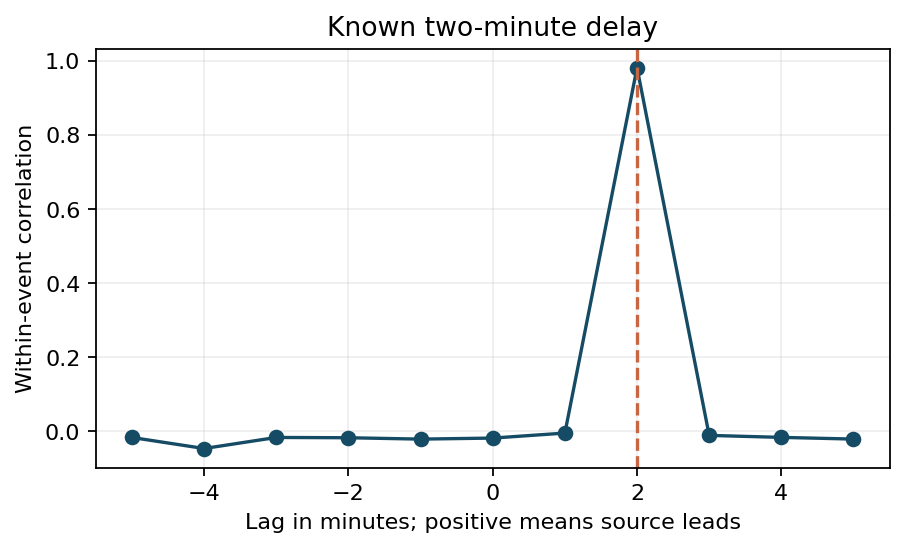

Notebook figure N04.1. Recovery of the known synthetic lead; simulated data.

In [2]:
rng = np.random.default_rng(62)
source = rng.normal(size=(80,40))
target = rng.normal(scale=.2,size=(80,40))
target[:,2:] += source[:,:-2]
lag_rows=[]
for lag in range(-5,6):
    a=source[:,:40-lag] if lag>=0 else source[:,-lag:]
    b=target[:,lag:] if lag>=0 else target[:,:40+lag]
    a=a-a.mean(axis=1,keepdims=True);b=b-b.mean(axis=1,keepdims=True)
    lag_rows.append({'lag_minutes':lag,'correlation':np.corrcoef(a.ravel(),b.ravel())[0,1]})
toy=pd.DataFrame(lag_rows)
assert toy.loc[toy.correlation.idxmax(),'lag_minutes']==2
show_table(toy, 'Table N04.1. Synthetic known-delay check: source leads target by two minutes.')
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(6.4,3.4))
ax.plot(toy.lag_minutes,toy.correlation,'o-',color='#164B65');ax.axvline(2,color='#C86542',ls='--')
ax.set(xlabel='Lag in minutes; positive means source leads',ylabel='Within-event correlation',title='Known two-minute delay');ax.grid(alpha=.2)
show_plot(fig,'Notebook figure N04.1. Recovery of the known synthetic lead; simulated data.')

event_type,source,target,lag_minutes,correlation,events
Minutes,EURUSD,SPX,0,0.397,50
Minutes,NSX,SPX,0,0.975,51
Minutes,SPX,EURUSD,0,0.397,50
Minutes,SPX,NSX,0,0.975,51
Statements,EURUSD,SPX,0,0.634,49
Statements,NSX,SPX,0,0.975,49
Statements,SPX,EURUSD,0,0.634,49
Statements,SPX,NSX,0,0.975,49


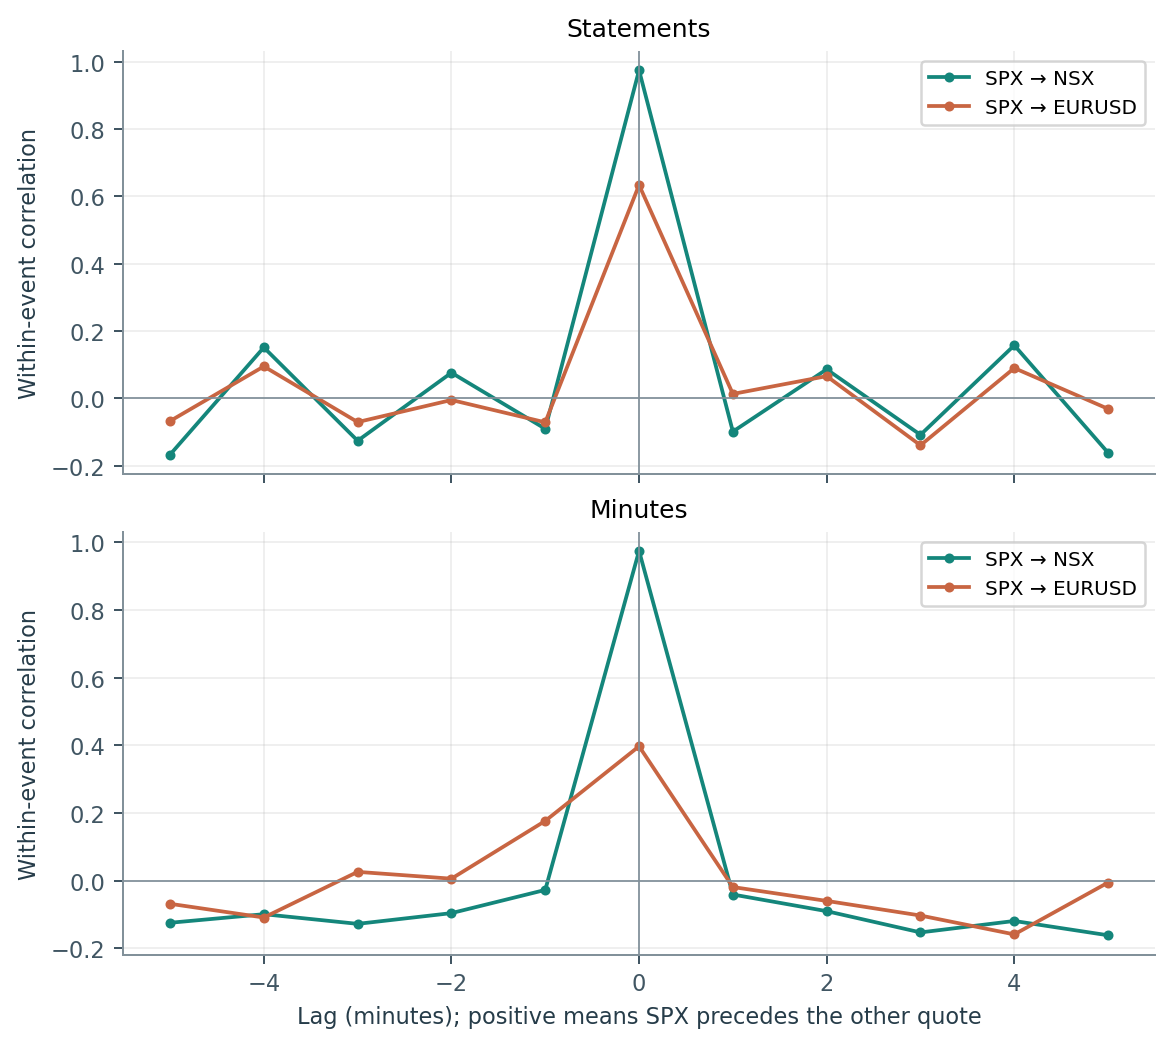

Figure 9. Pooled within-event minute-return correlations. A peak at zero is common co-movement; a nonzero-lag peak can also reflect quote timing or shared news and does not establish causation.

Equation (16). Predictive lead–lag association.
r^B_{e,t}=\mu_e+\sum_{j=1}^{3}\phi_j r^B_{e,t-j}+\sum_{j=1}^{3}\gamma_j r^A_{e,t-j}+u_{e,t}
Event fixed effects and own-return lags precede exploratory tests of the three cross-series lags; event-cluster uncertainty is approximate.

In [3]:
corr=table('lead-lag-correlations-pooled.csv')
peaks=corr.loc[corr.groupby(['event_type','source','target']).correlation.apply(lambda s:s.abs().idxmax())]
show_table(peaks[['event_type','source','target','lag_minutes','correlation','events']], 'Table N04.2. Largest absolute sample correlation across the displayed lags; descriptive selection only.')
show_figure(9)
equation(16)

## Conditioning on the target's own history

A persistent target can create a misleading source-return association. The regression therefore includes its own three lagged returns before adding three source-return lags, plus event fixed effects. Event-cluster CR1 uncertainty allows dependence within an event, but the finite number of clusters makes its Wald reference distribution approximate.

As Nickell (1981) shows in *Biases in dynamic models with fixed effects*, including lagged outcomes with fixed effects in short panels can bias coefficient estimates. Each event here contributes only 17 usable minute rows. Clustered standard errors do not remove that coefficient bias. The p-values below are descriptive diagnostics, with no project-wide multiplicity correction, causal interpretation or tradable-lead claim.

In [4]:
tests=table('lead-lag-tests-pooled.csv')
show_table(tests[['event_type','source','target','events','cross_lag_1','cross_lag_2','cross_lag_3','p_value_exploratory','incremental_R2']], 'Table N04.3. Exploratory dynamic fixed-effects diagnostics.')
from diffusion.empirical import data_for,panel
bars,ev=data_for(['development','validation','holdout'])
_,_,m,p=panel(bars,ev,'SPX','Statements')
_,_,mm,pp=panel(bars,ev,'NSX','Statements')
ids=m.index.intersection(mm.index)
a=10000*np.diff(np.log(p.loc[ids,np.arange(-1,20)].to_numpy()),axis=1)
b=10000*np.diff(np.log(pp.loc[ids,np.arange(-1,20)].to_numpy()),axis=1)
a-=a.mean(axis=1,keepdims=True);b-=b.mean(axis=1,keepdims=True)
zero=float(np.corrcoef(a.ravel(),b.ravel())[0,1])
saved=corr.query("event_type=='Statements' and source=='SPX' and target=='NSX' and lag_minutes==0").correlation.iloc[0]
assert np.isclose(zero,saved)
print(f'Recomputed zero-lag SPX/NSX correlation: {zero:.6f} across {len(ids)} events.')

event_type,source,target,events,cross_lag_1,cross_lag_2,cross_lag_3,p_value_exploratory,incremental_R2
Statements,SPX,NSX,49,-0.013,0.203,0.315,0.199,0.007
Statements,NSX,SPX,49,0.025,-0.090,-0.236,0.071,0.010
Statements,SPX,EURUSD,49,-0.000,0.037,-0.015,0.455,0.007
Statements,EURUSD,SPX,49,-0.146,-0.068,-0.023,0.514,0.005
Minutes,SPX,NSX,51,-0.210,0.008,-0.400,0.108,0.008
Minutes,NSX,SPX,51,0.223,-0.045,0.291,0.029,0.013
Minutes,SPX,EURUSD,50,0.009,-0.034,-0.025,0.049,0.011
Minutes,EURUSD,SPX,50,0.664,0.320,0.392,0.006,0.082


Recomputed zero-lag SPX/NSX correlation: 0.975012 across 49 events.


## Milestone outcome

The toy lead is recovered with an explicit sign convention, and the empirical lag diagnostics are reproducible. Shared news, asynchronous quote updates, stale prices, short-panel bias and exploratory selection prevent these diagnostics from proving information transmission or arbitrage. The main evidence remains the separately estimated event-response path.